In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

# Configuração estética (Seaborn)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [14, 8]
plt.rcParams['font.size'] = 12

print("Bibliotecas carregadas. Ambiente pronto para modelação avançada.")

Bibliotecas carregadas. Ambiente pronto para modelação avançada.


In [8]:
# 1. Carregar dados brutos da JHU
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df_raw = pd.read_csv(url)

# 2. Filtrar para o Brasil e transpor
df_brazil = df_raw[df_raw['Country/Region'] == 'Brazil'].drop(columns=['Province/State', 'Lat', 'Long', 'Country/Region']).T
df_brazil.columns = ['Confirmados']

# 3. Limpeza de dados
df_brazil.index = pd.to_datetime(df_brazil.index)
# Começamos a análise quando os casos estabilizaram acima de 5000 para evitar ruído inicial
df_brazil = df_brazil[df_brazil['Confirmados'] > 5000]

# 4. Criação dos vetores para o modelo
y_real = df_brazil['Confirmados'].values
x_dias = np.arange(len(y_real))
N = 214000000  # População estimada do Brasil

print(f"Dados processados: {len(x_dias)} dias de histórico (aprox. {len(x_dias)/365:.1f} anos).")

Dados processados: 1074 dias de histórico (aprox. 2.9 anos).


C:\Users\pedro\AppData\Local\Temp\ipykernel_20636\1082574491.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_brazil.index = pd.to_datetime(df_brazil.index)


In [9]:
def sirs_cumulative_model(y, t, N, beta, gamma, xi):
    S, I, R, C_acumulado = y
    
    # Taxa de contágio instantânea
    flow_inf = beta * S * I / N
    # Taxa de recuperação
    flow_rec = gamma * I
    # Taxa de perda de imunidade (Reinfecção)
    flow_loss = xi * R
    
    dSdt = -flow_inf + flow_loss
    dIdt = flow_inf - flow_rec
    dRdt = flow_rec - flow_loss
    dCdt = flow_inf  # Apenas conta os novos casos (para gráfico acumulado)
    
    return dSdt, dIdt, dRdt, dCdt

def fit_sirs(x, beta, gamma, xi):
    # Condições Iniciais
    I0 = y_real[0]      # Infectados iniciais (baseado nos dados)
    R0 = 0              # Recuperados iniciais
    S0 = N - I0         # Suscetíveis
    C0 = I0             # Casos Acumulados iniciais
    y0 = S0, I0, R0, C0
    
    # Integração
    ret = odeint(sirs_cumulative_model, y0, x, args=(N, beta, gamma, xi))
    S, I, R, C_acumulado = ret.T
    
    return C_acumulado

In [10]:
# Estimativa inicial [beta, gamma, xi]
# xi (perda de imunidade) costuma ser baixo (ex: 1/180 dias)
p0 = [0.15, 0.14, 0.001] 

# Limites para os parâmetros: (min), (max)
# Beta e Gamma entre 0 e 1. Xi entre 0 e 0.1
bounds = ([0, 0, 0], [2.0, 1.0, 0.1])

print("Iniciando otimização não-linear (pode demorar alguns segundos)...")

popt, pcov = curve_fit(fit_sirs, x_dias, y_real, p0=p0, bounds=bounds)
beta_opt, gamma_opt, xi_opt = popt

print("\n--- Parâmetros Descobertos pelo Modelo ---")
print(f"Beta (Transmissão): {beta_opt:.5f}")
print(f"Gamma (Recuperação): {gamma_opt:.5f} (Tempo médio ~{1/gamma_opt:.1f} dias)")
print(f"Xi (Perda de Imunidade): {xi_opt:.6f}")

if xi_opt > 0.00001:
    tempo_imunidade = 1/xi_opt
    print(f"Interpretação: O modelo sugere que a imunidade dura em média {tempo_imunidade:.0f} dias.")
else:
    print("Interpretação: O modelo tendeu para um SIR clássico (imunidade longa).")

Iniciando otimização não-linear (pode demorar alguns segundos)...

--- Parâmetros Descobertos pelo Modelo ---
Beta (Transmissão): 0.28934
Gamma (Recuperação): 0.27588 (Tempo médio ~3.6 dias)
Xi (Perda de Imunidade): 0.003458
Interpretação: O modelo sugere que a imunidade dura em média 289 dias.


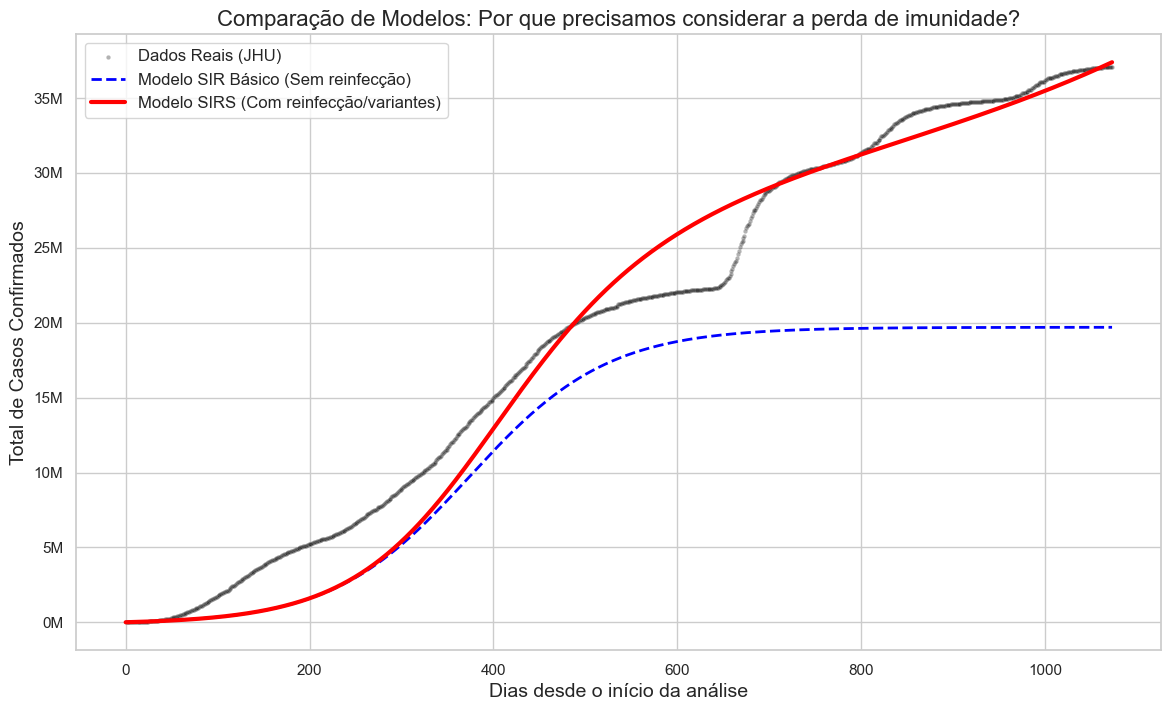

In [11]:
# 1. Gerar curva do SIRS Otimizado (Seu modelo sofisticado)
y_sirs = fit_sirs(x_dias, beta_opt, gamma_opt, xi_opt)

# 2. Gerar curva de um SIR Simples (para comparação)
# Forçamos xi=0 (sem perda de imunidade) para ver a diferença
y_sir_simple = fit_sirs(x_dias, beta_opt, gamma_opt, xi=0)

# Plotagem
plt.figure(figsize=(14, 8))

# Dados Reais
sns.scatterplot(x=x_dias, y=y_real, color='black', alpha=0.3, s=10, label='Dados Reais (JHU)')

# Modelo Simples (Linha Tracejada)
plt.plot(x_dias, y_sir_simple, color='blue', linestyle='--', linewidth=2, label='Modelo SIR Básico (Sem reinfecção)')

# Modelo Sofisticado (Linha Cheia)
plt.plot(x_dias, y_sirs, color='red', linewidth=3, label='Modelo SIRS (Com reinfecção/variantes)')

plt.title('Comparação de Modelos: Por que precisamos considerar a perda de imunidade?', fontsize=16)
plt.xlabel('Dias desde o início da análise', fontsize=14)
plt.ylabel('Total de Casos Confirmados', fontsize=14)

# Formatando eixo Y para milhões
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}M".format(int(x/1e6))))

plt.legend(fontsize=12)
plt.show()

In [12]:
r2_sirs = r2_score(y_real, y_sirs)
r2_simple = r2_score(y_real, y_sir_simple)

print("=== RELATÓRIO DE DESEMPENHO ($R^2$) ===")
print(f"Modelo SIR Básico: {r2_simple:.4f}")
print(f"Modelo SIRS (Seu Projeto): {r2_sirs:.4f}")

diferenca = (r2_sirs - r2_simple) * 100
print(f"\nConclusão: O modelo SIRS explica os dados {diferenca:.2f}% melhor que o modelo simples.")
print("Isso acontece porque a curva 'simples' satura (achata), enquanto a realidade continua crescendo.")

=== RELATÓRIO DE DESEMPENHO ($R^2$) ===
Modelo SIR Básico: 0.4866
Modelo SIRS (Seu Projeto): 0.9671

Conclusão: O modelo SIRS explica os dados 48.05% melhor que o modelo simples.
Isso acontece porque a curva 'simples' satura (achata), enquanto a realidade continua crescendo.
